# 09 · Quantization in practice

A 7B model in bf16 needs 14 GB just for its weights; in 4-bit it needs about 4 GB and fits on a laptop GPU. And since generating each token means reading every weight from memory once, fewer bytes per weight usually also means more tokens per second, *if* there is a kernel that computes directly on the packed weights.

**What you will learn**
1. *Under the hood*, in a few lines of torch: absmax scaling, why scales must be **per block** (outliers), and why **NF4** places its 16 levels unevenly.
2. *In practice*: quantize a real model (SmolLM2-360M-Instruct) with **optimum-quanto** to int8, float8, int4 and int2 weights.
3. *How to measure it*: memory, speed, perplexity, and the two metrics that catch damage perplexity hides: **KL divergence** to the original model and **top-1 agreement**.
4. What people use in production: bitsandbytes, GPTQ, AWQ, GGUF, FP8.

In [1]:
import os, sys, json, time, random, re, gc, copy, tempfile, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import transformers, peft, trl, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
transformers.utils.logging.set_verbosity_error()   # keep the notebook output to what we print ourselves
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
import huggingface_hub; huggingface_hub.utils.logging.set_verbosity_error()
set_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = device == "cuda" and torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if BF16 else torch.float32
# We share the GPU with Ollama, so we give this notebook a fixed VRAM budget. Going over it raises an
# out-of-memory error right away instead of silently spilling into (very slow) system RAM.
VRAM_BUDGET_GB = float(os.environ.get("VRAM_BUDGET_GB", 1.5))
if device == "cuda":
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    torch.cuda.set_per_process_memory_fraction(min(1.0, VRAM_BUDGET_GB / total))
    print(f"GPU: {torch.cuda.get_device_name(0)} ({total:.1f} GB), bf16: {BF16}, budget for this notebook: {VRAM_BUDGET_GB} GB")
else:
    print("No GPU found: running on CPU (expect it to be much slower)")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__, "| trl", trl.__version__)

def from_pretrained(cls, name, **kw):
    """Load from the local Hugging Face cache when the model is there, and download it otherwise."""
    try:
        return cls.from_pretrained(name, local_files_only=True, **kw)
    except OSError:
        return cls.from_pretrained(name, **kw)

def free():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

def reset_peak():
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()

def peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")

GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.4 GB), bf16: True, budget for this notebook: 1.5 GB
torch 2.14.1+cu130 | transformers 5.22.2 | peft 0.21.2 | trl 1.17.1


## 1. Under the hood: absmax, blocks and NF4

Symmetric **absmax** quantization to *b* bits maps a group of weights to integers with one scale per group:
$$s = \frac{\max|w|}{2^{b-1}-1},\qquad q = \mathrm{round}(w/s),\qquad \hat w = s\,q$$

One large weight sets the scale for its whole group, and every other weight in the group is rounded coarsely. Real LLM weights do have outliers. Let's look at a real matrix: the first MLP down-projection of SmolLM2-135M.

In [2]:
small = from_pretrained(AutoModelForCausalLM, "HuggingFaceTB/SmolLM2-135M-Instruct", dtype=torch.float32)
W = small.model.layers[0].mlp.down_proj.weight.detach().clone()          # shape (576, 1536)
del small; free()
print(f"shape {tuple(W.shape)}, std {W.std():.4f}, max |w| {W.abs().max():.3f} = {W.abs().max() / W.std():.0f} standard deviations")

def absmax_quant(w, bits, block=None):
    """Quantize and dequantize w with one absmax scale per tensor (block=None) or per group of `block` weights."""
    g = w.reshape(-1, block) if block else w.reshape(1, -1)
    scale = g.abs().amax(dim=1, keepdim=True) / (2 ** (bits - 1) - 1)
    return (torch.round(g / scale) * scale).reshape(w.shape)

def rel_err(w, w_hat):
    return ((w - w_hat).norm() / w.norm()).item()

for bits in (8, 4):
    print(f"{bits}-bit:", " | ".join(f"{name} {100 * rel_err(W, absmax_quant(W, bits, blk)):5.2f}%"
                                     for name, blk in [("per tensor", None), ("block 1536 (per row)", 1536), ("block 64", 64)]),
          "  (relative error of the weights)")

shape (576, 1536), std 0.1930, max |w| 2.875 = 15 standard deviations
8-bit: per tensor  3.39% | block 1536 (per row)  0.92% | block 64  0.63%   (relative error of the weights)
4-bit: per tensor 58.72% | block 1536 (per row) 16.65% | block 64 11.39%   (relative error of the weights)


Per-tensor 4-bit is unusable; small blocks make it workable. The price is one scale per block: with fp16 scales and blocks of 64, that is 16/64 = 0.25 extra bits per weight, so "4-bit" models really use about 4.25–4.5 bits per weight.

**NF4** (from QLoRA) goes further. Weights inside a block are roughly normally distributed, so instead of 16 evenly spaced levels it puts the levels at **quantiles of a normal distribution**: dense near zero, where most weights are, and sparse in the tails.

block 64: int4 error 11.39%  vs  NF4 error 9.31%


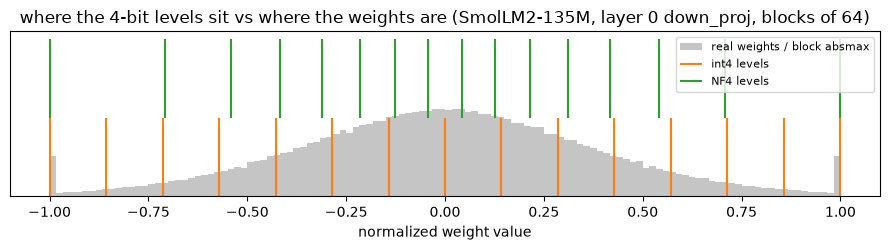

In [3]:
normal = torch.distributions.Normal(0, 1)
p = torch.linspace(0.5 / 16, 1 - 0.5 / 16, 16)
nf4 = normal.icdf(p); nf4 = nf4 / nf4.abs().max()                   # 16 levels in [-1, 1] at normal quantiles (a close variant of QLoRA's table)
int4 = torch.arange(-7, 8) / 7                                       # 15 evenly spaced levels of symmetric int4

def codebook_quant(w, levels, block=64):
    g = w.reshape(-1, block); scale = g.abs().amax(dim=1, keepdim=True)
    idx = ((g / scale).unsqueeze(-1) - levels).abs().argmin(-1)      # nearest level for every weight
    return (levels[idx] * scale).reshape(w.shape)

print(f"block 64: int4 error {100 * rel_err(W, codebook_quant(W, int4)):.2f}%  vs  NF4 error {100 * rel_err(W, codebook_quant(W, nf4)):.2f}%")

g = W.reshape(-1, 64); normed = (g / g.abs().amax(dim=1, keepdim=True)).flatten()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.hist(normed.numpy(), bins=120, density=True, alpha=.45, color="tab:gray", label="real weights / block absmax")
ax.vlines(int4, 0, 1.0, colors="tab:orange", label="int4 levels"); ax.vlines(nf4, 1.0, 2.0, colors="tab:green", label="NF4 levels")
ax.set_yticks([]); ax.set_xlabel("normalized weight value"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("where the 4-bit levels sit vs where the weights are (SmolLM2-135M, layer 0 down_proj, blocks of 64)")
plt.tight_layout(); plt.show()

## 2. Quantizing a real model with optimum-quanto

[`optimum-quanto`](https://github.com/huggingface/optimum-quanto) quantizes any PyTorch model in two calls: `quantize(model, weights=qint4)` swaps every `nn.Linear` for a `QLinear`, and `freeze(model)` replaces the float weights by packed integers plus scales. Under the hood it does what we just did: int8 and float8 use per-output-channel scales; int4 and int2 use groups of 128 weights with a scale and a zero-point each (affine instead of symmetric). Activations stay in bf16 (this is called **W8A16 / W4A16**). Quantizing activations too (`activations=qint8`) needs a calibration pass and pays off mostly on hardware with int8/fp8 matmuls.

We keep `lm_head` in bf16: in SmolLM2 it is tied to the input embedding, and the output layer is the most sensitive one.

> **Windows note.** For int4/int2, quanto unpacks the weights with a C++/CUDA kernel that it compiles on first use, which needs `ninja` and a C++ compiler. When those are missing, the cell below routes the op to an equivalent pure-PyTorch implementation (the same code as quanto's own reference version). It is slower, but it gives the same numbers.

In [4]:
from optimum.quanto import quantize, freeze, qint8, qint4, qint2, qfloat8

def unpack_py(packed, bits):
    """Pure-PyTorch unpacking of int4 / int2 values stored several per uint8 (quanto's reference implementation)."""
    return torch.cat([(packed & (2 ** (bits * (i + 1)) - 1)) >> (bits * i) for i in range(8 // bits)]).to(torch.uint8)

try:                                     # does the compiled kernel work here?
    torch.ops.quanto.unpack(torch.zeros(4, dtype=torch.uint8, device=device), 4)
    print("quanto's compiled unpack kernel works")
except Exception as e:
    torch.library.impl("quanto::unpack", ["CPU", "CUDA"])(unpack_py)
    print(f"compiled kernel unavailable ({type(e).__name__}); using the pure-PyTorch unpack")

quanto's compiled unpack kernel works


### Held-out text and the reference model

We measure on a few paragraphs of ordinary English that are not in this notebook's code or prompts. The reference is the **fp32** model (on CPU); everything else is compared against it, including bf16, which is itself a 16-bit approximation and gives us the "noise floor".

In [5]:
TEXT = """The town library opens at nine, but on Saturdays a small queue forms long before the doors are unlocked. Most of the people waiting are regulars: an old man who reads every newspaper from front to back, two students who claim the table by the window, and a mother with three children who each carry a bag of books to return. The librarian knows them all by name and greets them with the same question, asking what they are hoping to find today.
Cooking rice well is less about the recipe than about attention. Rinse the grains until the water runs almost clear, use a little less water than the packet suggests, and resist the urge to lift the lid. When the pot goes quiet, turn off the heat and let it rest for ten minutes. The steam finishes the work, and the rice comes out separate and tender instead of sticky.
In the late eighteenth century, canals were the fastest way to move heavy goods across England. A single horse walking along a towpath could pull a barge carrying thirty tons of coal, far more than it could drag on a muddy road. Within a few decades, however, the railways arrived, and many canals fell into disrepair. Today, restored stretches are used mostly by holiday boats, walkers and cyclists.
A good bug report saves everyone time. It says what you expected to happen, what actually happened, and the exact steps that make the problem appear. It includes the version of the software, the operating system and any error message, copied as text rather than described from memory. Above all, it is short: a developer should understand the problem in the first few lines.
The weather on the coast changed quickly that afternoon. By three o'clock the sky had turned grey, the wind picked up from the west, and the fishing boats began to return to the harbour one after another. People on the beach packed their towels and umbrellas, and within an hour the promenade was almost empty, except for a few dog walkers who did not seem to mind the rain.
Learning a musical instrument as an adult is slower than it is for a child, but it has its own advantages. Adults practise with a purpose, understand music theory more easily and can tell when something sounds wrong. The hardest part is patience: progress comes in small steps, and the first months often feel like a long series of mistakes before the first simple song finally sounds right."""

MODEL = "HuggingFaceTB/SmolLM2-360M-Instruct"
tok = from_pretrained(AutoTokenizer, MODEL)
ids = tok(TEXT, return_tensors="pt").input_ids
WINDOW = 256
windows = [ids[:, i:i + WINDOW] for i in range(0, ids.shape[1] - 1, WINDOW)]
print(f"{ids.shape[1]} tokens of held-out text in {len(windows)} windows of up to {WINDOW}")

@torch.no_grad()
def logprobs(model, dev):
    """Next-token log-probabilities of the model on every window, as fp32 on the CPU."""
    return [model(w.to(dev)).logits[0].float().log_softmax(-1).cpu() for w in windows]

t0 = time.time()
ref_model = from_pretrained(AutoModelForCausalLM, MODEL, dtype=torch.float32).eval()
REF = logprobs(ref_model, "cpu")
del ref_model; free()
print(f"fp32 reference computed on CPU in {time.time() - t0:.0f} s")

494 tokens of held-out text in 2 windows of up to 256


fp32 reference computed on CPU in 2 s


### The metrics

For each quantized model and every position of the held-out text:
- **perplexity** $=\exp(\text{mean NLL of the true next token})$: standard and cheap, but it averages over all tokens and on easy text small changes vanish in the noise;
- **KL(fp32 ‖ quant)** $=\sum_v p_{\text{fp32}}(v)\,\log\frac{p_{\text{fp32}}(v)}{p_{\text{quant}}(v)}$, averaged over positions: how far the *whole* next-token distribution moved. `llama.cpp` reports exactly this for its GGUF quants;
- **top-1 agreement**: the % of positions where both models' most likely token is the same. Roughly: "would greedy decoding say the same thing?";
- **weight memory** (bytes on the GPU) and **decode speed** (tokens per second, batch 1, greedy, 64 new tokens).

In [6]:
def drift(lp):
    nll = torch.cat([-l[:-1].gather(-1, w[0, 1:, None]).squeeze(-1) for l, w in zip(lp, windows)])
    kl = torch.cat([(r.exp() * (r - l)).sum(-1) for r, l in zip(REF, lp)])
    agree = torch.cat([(r.argmax(-1) == l.argmax(-1)).float() for r, l in zip(REF, lp)])
    return {"ppl": nll.mean().exp().item(), "kl": kl.mean().item(), "agree": agree.mean().item()}

@torch.no_grad()
def decode_speed(model, n_new=64):
    enc = tok.apply_chat_template([{"role": "user", "content": "Write a short story about a lighthouse keeper."}],
                                  add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
    model.generate(**enc, max_new_tokens=8, do_sample=False)                         # warm-up
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    out = model.generate(**enc, max_new_tokens=n_new, min_new_tokens=n_new, do_sample=False)
    if device == "cuda": torch.cuda.synchronize()
    return n_new / (time.time() - t0), tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)

ROWS = {}
fp32 = {"ppl": drift(REF)["ppl"], "kl": 0.0, "agree": 1.0}
ROWS["fp32 (CPU reference)"] = {**fp32, "mem": float("nan"), "tok_s": float("nan")}
print(f"fp32 reference: perplexity {fp32['ppl']:.2f}")

def measure(name, weights=None):
    free(); before = torch.cuda.memory_allocated() if device == "cuda" else 0
    model = from_pretrained(AutoModelForCausalLM, MODEL, dtype=torch.bfloat16 if BF16 else torch.float32).to(device).eval()
    if weights is not None:
        quantize(model, weights=weights, exclude=["lm_head"])
        freeze(model)
    free()
    mem = (torch.cuda.memory_allocated() - before) / 1e9 if device == "cuda" else float("nan")
    m = drift(logprobs(model, device))
    tok_s, sample = decode_speed(model)
    ROWS[name] = {**m, "mem": mem, "tok_s": tok_s, "sample": sample}
    print(f"{name:12s} weights {mem:5.2f} GB | ppl {m['ppl']:7.2f} | KL {m['kl']:.4f} | top-1 agree {100*m['agree']:5.1f}% | {tok_s:5.1f} tok/s")
    del model; free()

measure("bf16")
for name, w in [("int8", qint8), ("float8", qfloat8), ("int4 (g128)", qint4), ("int2 (g128)", qint2)]:
    measure(name, w)

fp32 reference: perplexity 17.16


bf16         weights  0.72 GB | ppl   17.13 | KL 0.0010 | top-1 agree  97.2% |  24.6 tok/s


int8         weights  0.41 GB | ppl   17.32 | KL 0.0048 | top-1 agree  96.6% |  17.4 tok/s


float8       weights  0.41 GB | ppl   17.13 | KL 0.0094 | top-1 agree  95.1% |  16.0 tok/s


int4 (g128)  weights  0.26 GB | ppl   22.16 | KL 0.2705 | top-1 agree  73.3% |  10.5 tok/s


int2 (g128)  weights  0.19 GB | ppl 227817.44 | KL 9.3993 | top-1 agree   1.4% |   8.0 tok/s


**Reading the numbers** (SmolLM2-360M, ~500 held-out tokens, everything compared with fp32):
- **bf16 is not exact either**: KL 0.001 and 97.2 % top-1 agreement. That is the noise floor: many next-token choices are near-ties, so even a 16-bit rounding flips about 3 % of them.
- **int8 and float8** cut the weights from 0.72 to 0.41 GB with KL 0.005–0.009 and ~96 % agreement: almost free. (The 0.41 GB includes the 94 MB tied embedding / `lm_head` we kept in bf16.) Perplexity says float8 is exactly as good as bf16 (17.13), yet its KL is twice int8's: **perplexity hides differences that KL shows**.
- **int4** (groups of 128) brings the weights to 0.26 GB, a third of bf16, but at a clear cost on a model this small: KL 0.27, only 73 % top-1 agreement, perplexity +29 % (17.16 → 22.16). The story it writes is still fluent, but it is a different story. Small models have less redundancy and suffer more from 4 bits; on 7B+ models, 4-bit with good methods typically costs only a few % of perplexity.
- **int2** destroys the model (1.4 % agreement, perplexity in the hundreds of thousands, word salad). Plain round-to-nearest does not work at 2 bits; it takes error-compensating methods (GPTQ-style, AQLM, QuIP#) or quantization-aware training.

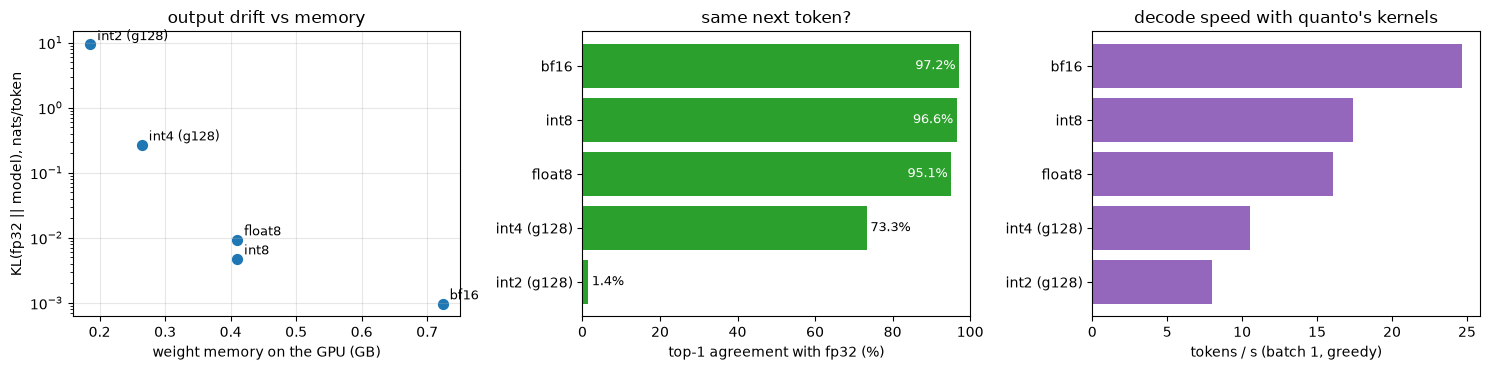

--- bf16: 'Once upon a time, in a small coastal town, there lived a lighthouse keeper named Jack. Jack was a kind soul who had spent his life tending to the lighthouse, a beacon of light that guided ships safely through the stormy '
--- int4 (g128): 'Lighthouse keeper, Jack, was a kind soul who lived near a small coastal town. He was known for his love of books and his love of the sea. He would often sit at the lighthouse, reading his favorite book, "The Story of the'
--- int2 (g128): '(. No," only, " l Lomb of lone,,, by, by,, All, w,,,ли, Partial,,,,",     ,"",.,.,,,,, о Ob, by, of., " and" M'


In [7]:
names = [n for n in ROWS if n != "fp32 (CPU reference)"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
mem = [ROWS[n]["mem"] for n in names]; kl = [max(ROWS[n]["kl"], 1e-5) for n in names]
ax[0].scatter(mem, kl, s=50)
for n, m_, k in zip(names, mem, kl): ax[0].annotate(n, (m_, k), xytext=(5, 3), textcoords="offset points", fontsize=9)
ax[0].set_yscale("log"); ax[0].set_xlabel("weight memory on the GPU (GB)"); ax[0].set_ylabel("KL(fp32 || model), nats/token")
ax[0].set_title("output drift vs memory"); ax[0].grid(alpha=.3)
ag = [100 * ROWS[n]["agree"] for n in names]
ax[1].barh(names, ag, color="tab:green"); ax[1].invert_yaxis(); ax[1].set_xlim(0, 100)
for i, a in enumerate(ag): ax[1].text(a + 1 if a < 85 else a - 1, i, f"{a:.1f}%", va="center", ha="left" if a < 85 else "right",
                                      color="black" if a < 85 else "white", fontsize=9)
ax[1].set_xlabel("top-1 agreement with fp32 (%)"); ax[1].set_title("same next token?")
ax[2].barh(names, [ROWS[n]["tok_s"] for n in names], color="tab:purple"); ax[2].invert_yaxis()
ax[2].set_xlabel("tokens / s (batch 1, greedy)"); ax[2].set_title("decode speed with quanto's kernels")
plt.tight_layout(); plt.show()

for n in ["bf16", "int4 (g128)", "int2 (g128)"]:
    print(f"--- {n}: {ROWS[n]['sample'][:220]!r}")

**Speed.** On this GPU the quantized models are **slower** than bf16 (24.6 tok/s → 17.4 for int8, 10.5 for int4). At batch 1, a 360M model is limited by kernel launches and Python overhead, not by memory bandwidth, so reading fewer bytes does not help, and quanto's quantized matmuls add unpacking and rescaling work on top. Real speedups need a **fused kernel** for the format on your hardware (Marlin / ExLlama for GPTQ, AWQ kernels, llama.cpp on CPU) and a model large enough to be bandwidth-bound. The memory saving is guaranteed; the speedup is not.

## 3. Quantization in production

| tool | what it does | typical use |
|---|---|---|
| **bitsandbytes** | `load_in_8bit` (LLM.int8(), outliers kept in fp16) and `load_in_4bit` (NF4 + double quantization of the scales), applied at load time, no calibration | **QLoRA**: fine-tune LoRA adapters on top of a frozen 4-bit base (`BitsAndBytesConfig` + `peft`) |
| **GPTQ** (`GPTQModel`) | quantizes layer by layer, using a small calibration set and second-order (Hessian) information to compensate the rounding error | 4-bit checkpoints served with fast W4A16 kernels (Marlin, ExLlama) in vLLM / TGI |
| **AWQ** (`AutoAWQ`, `llm-compressor`) | finds the ~1 % of channels with large *activations* and scales them before quantizing, so their weights lose less precision | 4-bit serving in vLLM; often a little better than GPTQ at the same size |
| **GGUF** (`llama.cpp`, Ollama, LM Studio) | k-quants: blocks of 32/256 weights with nested scales, 2–8 bits (`Q4_K_M`, `Q5_K_M`, `Q8_0`…) | CPU, Apple Silicon and consumer GPUs. The `qwen2.5:3b` model this course runs in Ollama is a `Q4_K_M` GGUF |
| **FP8** (`llm-compressor`, TensorRT-LLM, vLLM) | 8-bit floating point weights *and* activations, with native matmuls on Hopper / Ada / Blackwell GPUs | the default for large-scale serving: almost lossless, about 2× the throughput of bf16 |
| **torchao** | PyTorch-native int8 / int4 / fp8 (weights and activations), works with `torch.compile` | PyTorch serving and quantization-aware training |
| **KV-cache quantization** | stores the attention cache in fp8 / int8 | long contexts, where the cache can be bigger than the weights |

**How to evaluate a quantized model before you ship it**
1. KL and top-1 agreement against the original on text like your traffic (this notebook): cheap and sensitive.
2. Perplexity delta: standard, but it can hide damage on specific skills.
3. **Task accuracy on your own eval set**: math, code, long context and multilingual ability tend to break first.
4. Memory and speed **on the target hardware with the real kernel** (Marlin / AWQ kernels on GPU, llama.cpp on CPU). A format without a fused kernel saves memory but can be slower than bf16, as quanto's int4 path was here.
5. Bigger models tolerate quantization better: a 4-bit 7B model usually beats an 8-bit 3B model of the same size in GB.

## Takeaways

- Quantization = integers plus **scales per small block**. Outliers make per-tensor scales useless; NF4 spends its levels where the weights are.
- int8 and fp8 weights were almost free in quality (~96 % top-1 agreement). int4 with groups is the usual sweet spot for 7B+ models, but on our 360M model it cost a quarter of the top-1 agreement, so measure on *your* model. Naive 2-bit destroys the model.
- Measure **KL and top-1 agreement**, not only perplexity, and then your task metric.
- Memory savings are guaranteed; speed depends on having a kernel for the format on your hardware.

**Next:** `10_rag.ipynb`.